<center><h1> ETI195 - Ética para Ciencia de Datos y Estadística </h1><center>
<center><h2> Taller Sumativo 3: Modelos interpretables y xAI <h2><center>  




# `Instrucciones generales`

Esta es la parte III del proyecto, considerá ultizar tus resultados anteriores
y reciclar el código anterior.

## `Temas formales`

**Modalidad**: Grupos de 3 personas.

**Formato de entrega:** El trabajo debe entregarse a través de Canvas, tanto en formato Jupyter ejecutable (.ipynb) como en formato PDF.

**Formalidades de las respuestas:**
- Citas: APA 7.
- Se espera buena ortografía y redacción, con respuestas en tono académico.
- No respondan con simples "si" o "no" , considera argumentar tu respuestas y justificar con bibliografía si lo estimas necesario.

## `Recomendaciones`

- Asistan a los talleres formativos, revisen los ejemplos de código y consulten sus dudas con sus ayudantes.

- **Lean la rúbrica antes de hacer su tarea.**

## `Integridad académica y uso de IA`

El uso de asistentes de IA sigue los lineamientos de integridad académica del curso, con las siguientes excepciones:

- Pueden usar IA para consultar por bugs y entender mejor el código.
- Pueden usar IA para generar las representaciones visuales que estimen convenientes.

Si tienen dudas sobre el uso de IA o la citación de código externo, no duden en preguntar. Pueden usar libremente los códigos de los talleres formativos. <3


- **`transformers`** (Hugging Face): provee modelos de lenguaje preentrenados listos para usar. En particular, usaremos el pipeline `sentiment-analysis` con el modelo **BETO**, un BERT entrenado en español.

- **`lime`**: implementación de la técnica LIME. El módulo `lime_text` está diseñado específicamente para datos de texto.

Primera celda ejecutarla individualmente, luego reiniciar Kernel y posterioremente ejecutar las demás celdas

In [1]:
# Coloque aquí todas las importaciones que considere necesarias.
from transformers import pipeline
from lime.lime_text import LimeTextExplainer
import numpy as np
import matplotlib.pyplot as plt

# Parte 1: Interpretabilidad local con LIME

## Motivación

Un modelo de clasificación de texto puede tener buen desempeño agregado y aun así fallar sistemáticamente ante ciertos tipos de lenguaje: eufemismos, tecnicismos, formas indirectas de comunicar una noticia, o lenguaje cargado políticamente. Estas fallas suelen ser invisibles si solo miramos métricas globales o si confiamos ciegamente en el sistema. LIME permite explorar una predicción individual y preguntar: ¿qué palabras llevaron al modelo a decidir esto? Esto es especialmente relevante cuando el texto que se clasifica admite múltiples interpretaciones, tiene una carga social relevante y, en definitiva, forma parte de un sistema con consecuencias reales sobre las personas.

En esta parte van a diseñar un pequeño experimento: eligen un contexto de riesgo asociado a su proyecto, construyen frases que pongan a prueba ese riesgo específico, y usan LIME para ver si el modelo efectivamente falla (o no) de la manera que hipotetizaron.

## Parte 1.1: Contexto

Lo primero que deben hacer es definir el contexto de su análisis. Dependiendo del proyecto que su grupo haya escogido, elijan un escenario en el que un sistema sociotécnico relacionado con su dataset tuviera que clasificar lenguaje, y en el que un error de clasificación tuviera una consecuencia concreta. Por ejemplo:

- **CIRI**: un sistema que clasifica declaraciones oficiales de gobiernos para detectar lenguaje que minimiza o niega violaciones a los derechos humanos.

- **Breast Cancer**: un sistema que analiza cómo se comunica un diagnóstico a pacientes.

- **CASEN**: un sistema que clasifica comunicaciones de resultados de ayudas sociales.


**Responder:**

0. Explica los conceptos clave: XAI, LIME y SHAP y lo que se busca hacer con estos en el contexto del taller.

***xAI***

Se utiliza para describir un modelo de IA, su impacto previsto y posibles sesgos. Esta herramienta ayuda a comprender y confiar en los resultados creados por algoritmos de machine learning. De esta manera los desarrolladores pueden estar seguros que el sistema funciona como se esperaba (concepto de interpretabilidad)

SHAP y LIME son herramientas de XAI, ambos son técnicas diseñadas para aplicarse en Black Box Models


LIME es una técnica de interpretabilidad local aplicada a texto, es decir, solo explica la predicción del modelo para una instancia especifica.
Sirve para identificar que palabras de texto están influyendo en que el modelo clasifique el texto como positivo o negativo.


SHAP es una técnica de interpretabilidad global y local que asigna numéricamente cuanto afecta cada variable a la predicción del modelo. Este algoritmo puede explicar de manera fiel las predicciones de cualquier clasificador. 


info de xAI: https://www.ibm.com/mx-es/think/topics/explainable-ai

info de LIME & SHAP: jupyter taller formartivo 3.1 y 3.2

1. Describan el escenario de riesgo que eligieron: ¿qué tipo de frases van a analizar y por qué esas frases son relevantes para ese escenario? Creen o recopilen al menos 10 frases.

Derechos: `Freedom of Religion (New)` y `Women's Social Rights`
Escenario de riesgo: Violación a alguno de estos derechos.

Frases de violación a estos derechos:


Titulares Positivos (Avances Sociales)

- «Chile promulga ley que obliga a empresas a medir y reportar públicamente su brecha salarial de género»
    - [Contexto de estudio: Representa la transición de las "buenas prácticas voluntarias" a obligaciones legales fiscalizables en América Latina. En paralelo, multinacionales mineras de la región (como BHP) han anunciado la erradicación total de su brecha salarial para cargos equivalente.](https://www.google.com/url?sa=t&source=web&rct=j&url=https%3A%2F%2Fwww.buk.cl%2Frecursos%2Festudios%2Fresultados-encuesta-ley-brecha-salarial-chile&ved=0CAEQ1fkOahcKEwjg78L2js6XAxUAAAAAHQAAAAAQDg&opi=89978449)
- «Orden ejecutiva en EE. UU. impulsa financiamiento e investigación médica exclusiva para la salud de las mujeres»
    - [Contexto de estudio: Aborda el sesgo histórico de género en la investigación biomédica para garantizar que los diagnósticos y tratamientos se adapten a las necesidades específicas de la salud femenina en todas las etapas de la vida.](https://www.google.com/url?sa=t&source=web&rct=j&url=https%3A%2F%2Fwww.whitehouse.gov%2Fpresidential-actions%2F2026%2F10%2Fadvancing-womens-health-to-improve-outcomes-in-all-phases-of-life%2F&ved=0CAEQ1fkOahcKEwjg78L2js6XAxUAAAAAHQAAAAAQEw&opi=89978449)
- «Reformas en el derecho de familia han dado acceso económico a más de 600 millones de mujeres en las últimas décadas»
	- [Contexto de estudio: De acuerdo con informes de ONU Mujeres, el desmantelamiento progresivo de marcos legales discriminatorios ha permitido avances significativos en derechos hereditarios, de propiedad y autonomía financiera.](https://www.google.com/url?sa=t&source=web&rct=j&url=https%3A%2F%2Fwww.globalcompactnetwork.org%2Fen%2Fnews%2Fungcn-italy-news%2F2723-womens-rights-are-regressing-all-over-the-world-the-alarm-raised-by-the-united-nations.html&ved=0CAEQ1fkOahcKEwjg78L2js6XAxUAAAAAHQAAAAAQGw&opi=89978449)
- «Organizaciones sindicales celebran nuevos derechos laborales por trastornos menopáusicos y violencia de género»
	- [Contexto de estudio: Casos de estudio europeos (como las pautas impulsadas por la UGT) muestran la creación de incapacidades temporales adaptadas a la salud reproductiva de las mujeres y protecciones de corresponsabilidad en el cuidado familiar.](https://www.google.com/url?sa=t&source=web&rct=j&url=https%3A%2F%2Fwww.ugt.es%2Fugt-celebra-los-nuevos-derechos-para-las-mujeres-trabajadoras-y-las-familias-con-responsabilidades&ved=0CAEQ1fkOahcKEwjg78L2js6XAxUAAAAAHQAAAAAQIA&opi=89978449)
- «Mujeres de Afganistán desafían las prohibiciones del régimen talibán a través de protestas digitales»
	- [Contexto de estudio: La resiliencia social y el activismo en el exilio utilizan las plataformas en línea para organizarse y denunciar el apartheid de género, a pesar de las graves represalias físicas.](https://www.google.com/url?sa=t&source=web&rct=j&url=https%3A%2F%2Fwww.globalissues.org%2Fnews%2Ftopic%2F166&ved=0CAEQ1fkOahcKEwjg78L2js6XAxUAAAAAHQAAAAAQJQ&opi=89978449)

Titulares Negativos (Retrocesos y Brechas Persistentes)

- «ONU alerta: Un tercio de las instituciones creadas para avanzar en la igualdad de género perdieron poder o presupuesto»
	- [Contexto de estudio: Revela un "retroceso político deliberado" a nivel global. El financiamiento para organizaciones de derechos de las mujeres ha caído a sus niveles más bajos, debilitando los mecanismos institucionales.](https://www.google.com/url?sa=i&source=web&rct=j&url=https://www.unwomen.org/en/news-stories/press-release/2026/09/one-in-three-institutions-built-to-advance-gender-equality-stripped-of-power-in-just-two-years-new-un-report-reveals&ved=2ahUKEwiT5qzzjs6XAxUtrpUCHfS8J6MQ0YISegoIAggACAAIMRAF&opi=89978449&cd&psig=AOvVaw3pwbm_H8HoOpPp8pyhTyzo&ust=1792775389615000)
- «A escala mundial, las mujeres poseen solo el 64% de los derechos legales que disfrutan los hombres»
	- [Contexto de estudio: El lema del Día Internacional de la Mujer destaca que ningún país ha alcanzado la plena igualdad jurídica. Al ritmo actual, cerrar las brechas legales tomará 286 años.](https://www.google.com/url?sa=t&source=web&rct=j&url=https%3A%2F%2Fwww.unwomen.org%2Fes%2Fnoticias%2Fcomunicado-de-prensa%2F2026%2F03%2Fningun-pais-del-mundo-ha-alcanzado-la-plena-igualdad-juridica-para-las-mujeres-y-ninas&ved=0CAEQ1fkOahcKEwjg78L2js6XAxUAAAAAHQAAAAAQLw&opi=89978449)
- «Escalación de conflictos y crisis climática exacerban la inseguridad alimentaria para millones de mujeres y niñas»
	- [Contexto de estudio: Los desastres ambientales y las guerras profundizan las desigualdades de cuidados. Las mujeres dedican colectivamente 250 millones de horas al día solo a recolectar agua, lo que reduce drásticamente su acceso a la educación y al empleo formal.](https://www.google.com/url?sa=t&source=web&rct=j&url=https%3A%2F%2Flac.unwomen.org%2Fes%2Fstories%2Fnoticia%2F2026%2F10%2Flas-mujeres-agricultoras-y-la-igualdad-de-genero&ved=0CAEQ1fkOahcKEwjg78L2js6XAxUAAAAAHQAAAAAQNA&opi=89978449)
    - [otra fuente](https://www.google.com/url?sa=t&source=web&rct=j&url=https%3A%2F%2Fwww.globalissues.org%2Fnews%2Ftopic%2F166&ved=0CAYQ1fkOahcKEwjg78L2js6XAxUAAAAAHQAAAAAQNA&opi=89978449)
- «Ciberacoso sin freno: El 44% de las mujeres del mundo viven en países sin leyes de protección contra la violencia digital»
	- [Contexto de estudio: El avance de la Inteligencia Artificial y la falta de marcos jurídicos frente al acoso digital están forzando la autocensura de activistas, políticas y periodistas en redes sociales.](https://www.google.com/url?sa=t&source=web&rct=j&url=https%3A%2F%2Fnews.un.org%2Fes%2Fstory%2F2025%2F03%2F1537106&ved=0CAsQ1fkOahcKEwjg78L2js6XAxUAAAAAHQAAAAAQPA&opi=89978449)
- «Disminuye la presencia de mujeres en parlamentos y liderazgos políticos por primera vez en dos décadas»
	- [Contexto de estudio: Datos de la Unión Interparlamentaria (IPU) indican un estancamiento en la representación política formal. Además, las pocas mujeres ministras suelen ser relegadas exclusivamente a carteras de cuidados o igualdad social, con baja presencia en las áreas de Defensa o Interior.](https://www.google.com/url?sa=t&source=web&rct=j&url=https%3A%2F%2Felpais.com%2Fplaneta-futuro%2F2026-09-17%2Flas-mujeres-pierden-poder-en-un-mundo-cada-vez-mas-hostil-a-la-igualdad-segun-la-onu.html&ved=0CAEQ1fkOahcKEwjg78L2js6XAxUAAAAAHQAAAAAQRw&opi=89978449)
    - [otra fuente](https://www.google.com/url?sa=t&source=web&rct=j&url=https%3A%2F%2Fwww.biobiochile.cl%2Fnoticias%2Fsociedad%2Fdebate%2F2026%2F07%2F18%2Flos-derechos-de-las-mujeres-estan-retrocediendo-las-senales-que-desatan-preocupacion-mundial.shtml&ved=0CAYQ1fkOahcKEwjg78L2js6XAxUAAAAAHQAAAAAQRw&opi=89978449)

In [2]:
frases = ["Chile promulga ley que obliga a empresas a medir y reportar públicamente su brecha salarial de género",
          "Orden ejecutiva en EE. UU. impulsa financiamiento e investigación médica exclusiva para la salud de las mujeres",
          "Reformas en el derecho de familia han dado acceso económico a más de 600 millones de mujeres en las últimas décadas",
          "Organizaciones sindicales celebran nuevos derechos laborales por trastornos menopáusicos y violencia de género",
          "Mujeres de Afganistán desafían las prohibiciones del régimen talibán a través de protestas digitales",
          "ONU alerta: Un tercio de las instituciones creadas para avanzar en la igualdad de género perdieron poder o presupuesto",
          "A escala mundial, las mujeres poseen solo el 64% de los derechos legales que disfrutan los hombres",
          "Escalación de conflictos y crisis climática exacerban la inseguridad alimentaria para millones de mujeres y niñas",
          "Ciberacoso sin freno: El 44% de las mujeres del mundo viven en países sin leyes de protección contra la violencia digital",
          "Disminuye la presencia de mujeres en parlamentos y liderazgos políticos por primera vez en dos décadas"]

#### Hipotesis

Hay lugares en los que se defienden los derechos de la mujer mientras que en otros se lo ataca como algo negativo.

## Parte 1.2: Aplicación de LIME

1. Carguen el modelo BETO de análisis de sentimientos.

In [3]:
clasificador = pipeline(
    "sentiment-analysis",
    model="finiteautomata/beto-sentiment-analysis",
    tokenizer="finiteautomata/beto-sentiment-analysis"
)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

2. Obtengan la predicción del modelo para cada frase y comparen los resultados con su hipótesis de 1.1: ¿se cumplió lo que esperaban?

In [4]:
print("Predicciones del modelo\n")
for frase in frases:
    resultado = clasificador(frase)[0]
    print(f"Frase     : {frase}")
    print(f"Sentimiento: {resultado['label']} (confianza: {resultado['score']:.2%})\n")

Predicciones del modelo

Frase     : Chile promulga ley que obliga a empresas a medir y reportar públicamente su brecha salarial de género
Sentimiento: NEU (confianza: 68.51%)

Frase     : Orden ejecutiva en EE. UU. impulsa financiamiento e investigación médica exclusiva para la salud de las mujeres
Sentimiento: NEU (confianza: 95.60%)

Frase     : Reformas en el derecho de familia han dado acceso económico a más de 600 millones de mujeres en las últimas décadas
Sentimiento: POS (confianza: 78.65%)

Frase     : Organizaciones sindicales celebran nuevos derechos laborales por trastornos menopáusicos y violencia de género
Sentimiento: NEU (confianza: 90.57%)

Frase     : Mujeres de Afganistán desafían las prohibiciones del régimen talibán a través de protestas digitales
Sentimiento: NEU (confianza: 98.51%)

Frase     : ONU alerta: Un tercio de las instituciones creadas para avanzar en la igualdad de género perdieron poder o presupuesto
Sentimiento: NEG (confianza: 99.84%)

Frase     : A 

### Respuesta 1.2.2

Frase 1: 
- pensamos que esta frase deberia ser positiva pero BETO la clasifica como neutro con una confiaza mayor al 50%

Frase 2:
- Esta frase debería ser clasificada como muy positiva pero BETO lo clasifico como MUY neutro, con lo cual no estamos de acuerdo.

Frase 3:
- Esta frase es positiva y estamos de acuerdo con BETO

Frase 4:
- Esta frase también deberia ser positiva pero BETO la clasifico como neutra con más de 90% de confianza.

Frase 5:
- Por una parte, esta frase podría ser una oración positiva porque las mujeres se estan defendiendo de la opresión; por otro lado, puede ser negativa porque las mujeres se ven en la necesidad de exponerse a ser acosadas digitalmente. Claramente no debería ser neutra pero es dificil clasificarla correctamente.

Frase 6:
- Esta frase es negativa y esta muy de acuerdo con la clasificación de BETO.

Frase 7:
- Esta frase es negativa por razones obvias y BETO la clasifico bien de acuerdo a nuestra hipotesis.

Frase 8:
- Esta frase es lamentablemente negativa y BETO nuevamente le acertó a nuestro ideal.

Frase 9:
- Esta frase es negativa y estamos de acuerdo con BETO

Frase 10:
- Esta frase es lametable y BETO le acertó a nuestro planteamiento.

3. Apliquen LIME para obtener la explicación local de al menos 5 frases, priorizando aquellas donde el modelo se comportó de forma inesperada o donde identifiquen un problema ético. Si no encuentran ningún problema, justifiquen esa conclusión. Para cada una, visualicen las contribuciones de cada palabra mediante un gráfico de barras.

In [5]:
def predecir_proba(textos):
    """
    Envuelve el pipeline de Hugging Face en el formato que espera LIME:
    recibe una lista de textos y retorna una matriz (n_textos x 3) con
    probabilidades para las clases NEG, NEU y POS.

    Aproximación: la probabilidad de la clase predicha es el score del modelo;
    el resto se distribuye uniformemente entre las otras dos clases.
    """
    etiquetas = ["NEG", "NEU", "POS"]  # orden fijo requerido por LimeTextExplainer
    resultados = clasificador(list(textos), top_k=None)
    probas = []
    for r in resultados:
        scores = {d["label"]: d["score"] for d in r}
        probas.append([scores[e] for e in etiquetas])
    return np.array(probas)

# Instanciamos el explicador LIME con los nombres de las clases del modelo
explainer = LimeTextExplainer(class_names=["NEG", "NEU", "POS"])

In [6]:
def graf_pesos(frase):
    frase_a_explicar = frase.strip()

    # Clase predicha por el modelo
    probs = predecir_proba([frase_a_explicar])[0]
    clase_idx = int(np.argmax(probs))
    nombre_clase = explainer.class_names[clase_idx]

    # Obtener explicación para  esa clase
    exp = explainer.explain_instance(
        frase_a_explicar,
        predecir_proba,
        labels=(clase_idx,),
        num_features=len(frase_a_explicar.split()),
        num_samples=500
    )

    # Extraemos los pesos (contribuciones) de cada palabra
    explicacion = exp.as_list(label=clase_idx)
    palabras = [item[0] for item in explicacion]
    pesos    = [item[1] for item in explicacion]

    # Barras empujan hacia la clase que se busca predecir
    fig, ax = plt.subplots(figsize=(10, 5))
    colores = ['green' if p > 0 else 'red' for p in pesos] # los colores se asignan para ver que palabras empujan a la clase predicha.
    ax.barh(palabras, pesos, color=colores, alpha=0.75)
    ax.set_xlabel(f'Contribución a la clase predicha: {nombre_clase}')
    ax.set_title(f'Explicación LIME ({nombre_clase}, p={probs[clase_idx]:.2f}): "{frase_a_explicar}"')
    ax.axvline(x=0, color='black', linestyle='-', linewidth=0.8)
    plt.tight_layout()
    plt.show()

[7, 9, 5, 4, 2]
7 - Escalación de conflictos y crisis climática exacerban la inseguridad alimentaria para millones de mujeres y niñas
9 - Disminuye la presencia de mujeres en parlamentos y liderazgos políticos por primera vez en dos décadas
5 - ONU alerta: Un tercio de las instituciones creadas para avanzar en la igualdad de género perdieron poder o presupuesto
4 - Mujeres de Afganistán desafían las prohibiciones del régimen talibán a través de protestas digitales
2 - Reformas en el derecho de familia han dado acceso económico a más de 600 millones de mujeres en las últimas décadas


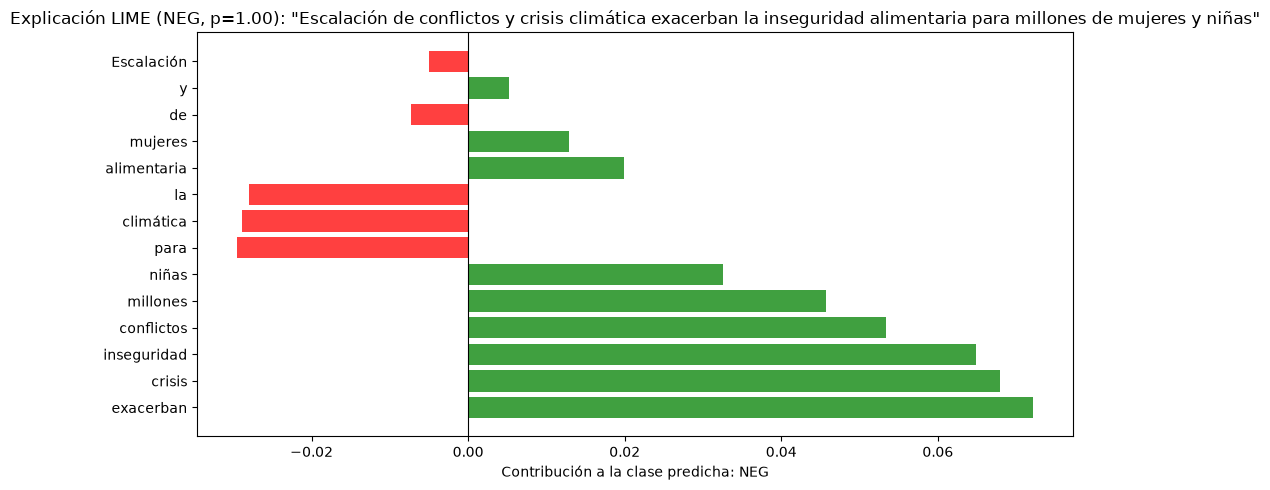

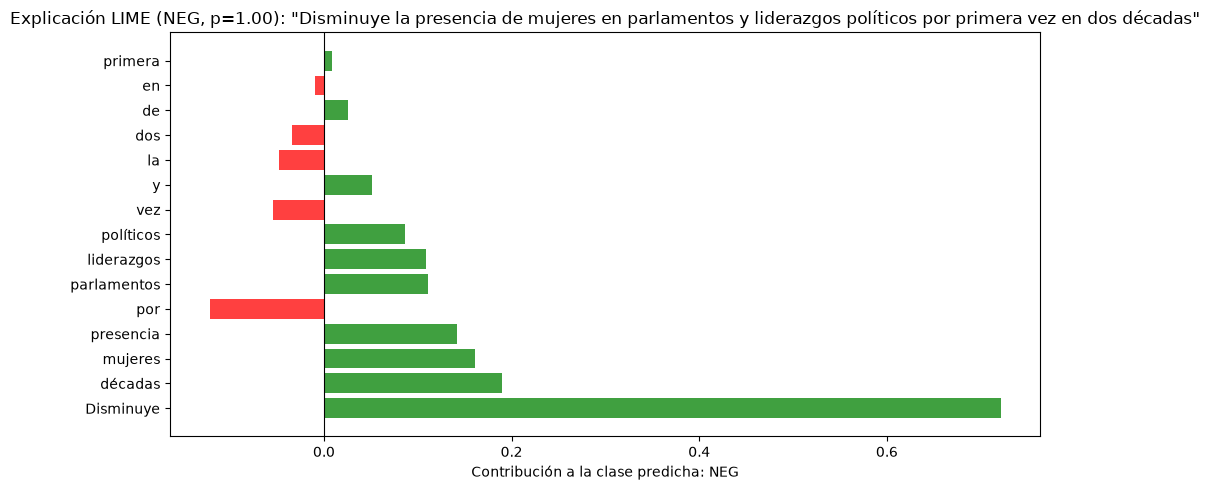

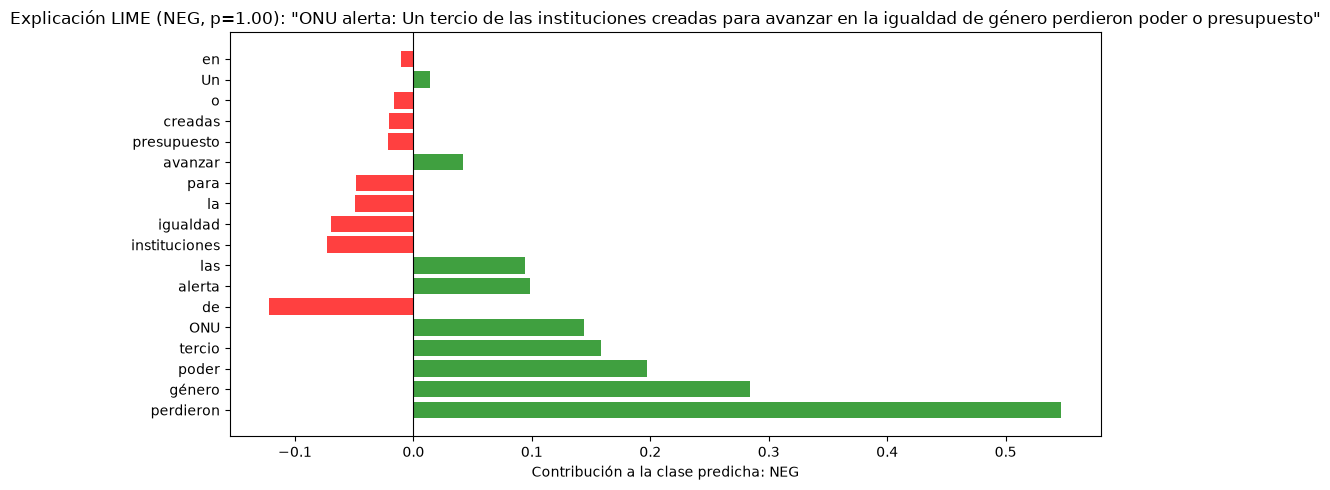

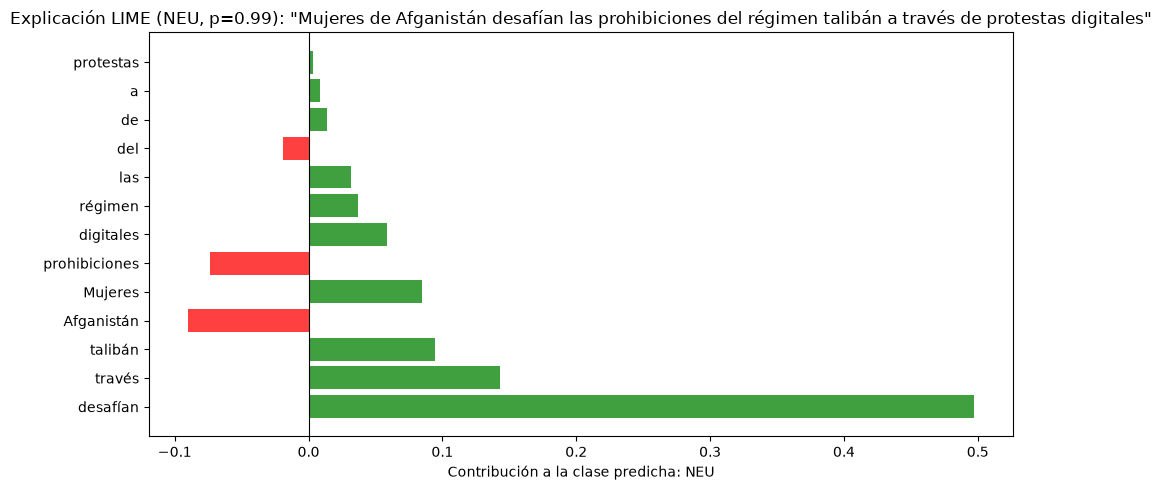

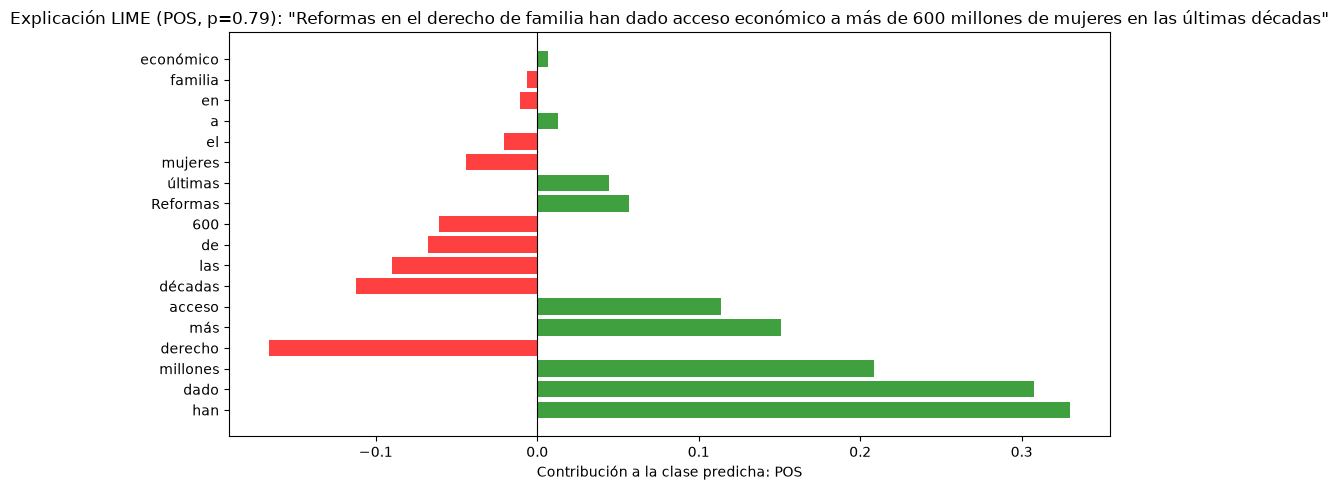

In [7]:
# indices al azar de la lista de frases
import random
random.seed(9)
# 5 indices aleatorios
i = [random.randint(0, 10) for _ in range(5)]
print(i)

fras = [frases[i[0]], frases[i[1]], frases[i[2]], frases[i[3]], frases[i[4]]]
j = 0
for f in fras:
    print(f"{i[j]} - {f}")
    j += 1

for f in fras:
    graf_pesos(f)

### Respuesta 1.2.3

El gráfico 4 (frase:"Mujeres de Afganistán desafían las prohibiciones del régimen talibán a través de protestas digitales") representa para nosotros un problema ético, debido a la dificultad para clasificarla.

4. Interpreten los resultados: ¿qué palabras están dominando cada predicción? ¿El modelo se apoya en las palabras que ustedes esperaban, o en otras? ¿Identifican un problema ético o social en los resultados?

### Respuesta 1.2.4

**Grafico 1**
- Las palabras con mayor peso negativo son "inseguridad, crisis, exacerban, conflicto"
- El modelo en esta oración coincide con nuestra observación, pero se puede destactar que la tercera palabra más pesada "exacerban" por si misma no es una palabra negativa. Sin embargo por el contexto se vuelve una palabra negativa

**Gráfico 2**
- Las palabras con mayor peso negativo son "Disminuye, mujeres, parlamentos"
- Historicamente la presencia de mujeres en ámbitos politicos es minima en comparación con el genero masculino. En el gráfico se observa que las palabras "mujeres y parlamentos" fueron clasificada como palabras negativas, a pesar que esta palabras por si solas son neutras.

**Gráfico 3**
- Las palabras con mayor peso negativo son "perdieron, género, tercio"
- Desde nuestro analisis las palabras negativas son "perdieron y alerta", lo cual coincidice parcialmente con lo que entrega BETO.

**Gráfico 4**
- Las palabras con mayor peso hacia la neutralidad son "desafian, través, Mujeres"
- Es extraño que en un contexto neutro la palabra "desafían", que generalmente representa "dificultad", de tanto peso a la neutralidad.

**Gráfico 5**
- Las palabras con mayor peso positivo son "millones, han, dado"
- Existe mucho contraste entre las variables con mucho peso positivo y las variables contrapeso. Además es dificil de comprender por qué las palabra "han" estan positiva y la palabra "de" tiene tanto contra peso, cuando los conectores no deberían influir tanto.



# Parte 2 : Explicabilidad de Random Forest con SHAP


En esta segunda parte del taller continuarán el trabajo anterior. Usando la limpieza y estandarización que ya realizaron, entrenen ahora un modelo Random Forest. Recuerden que, como mínimo, en la parte anterior debieron haber realizado los siguientes pasos:

2.1 Carga y limpieza de datos

- Revisión de qué columnas tienen nulos o datos faltantes y manejo de estos mediante: 0, botar fila/columna, o imputación de media.

- Revisión del tipo de dato del dataset y de los cambios realizados, si corresponde.

- Codificación de las variables categóricas, ya sea con label encoder, one-hot encoder, dummies, o mapeo manual en caso de columnas binarias.


## `Librerias`

In [8]:
import pandas as pd
import shap

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler,MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

In [10]:
# SEED que se usara para este taller (la misma del taller anterior)

SEED = 42

2.2 División del conjunto de datos
- separe del conjunto total los predictores y **la variable objetivo **
- Utilice train_test_split para obtener el conjunto de prueba y entrenamiento.

(La variable objetivo no difiere de la utilizada en el taller anterior)



2.3 Estandarización
- Estandarice los datos numéricos con StandarScaler o Minmax
- Justifique brevemente su elección






2.4 Clasificador Random Forest y métrica de evaluación
- Entrenen un Random Forest, seleccionen un número de estimadores y entreguen las predicciones del modelo.
- Comenten los resultados de la matriz de confusión y del reporte de clasificación. Expliquen las consecuencias de aplicar ese modelo específico en el área que abarca su proyecto.

2.5 Resultado y explicaciones con SHAP
- Comenta los beneficios y perjuicios que puede tener una herramienta como SHAP, en general y aterriza al caso de los datos trabajados
- Obten los valores shap.Visualiza el summary plot. Comenta los resultados.
- Analiza que features son importantes para la predicción y que puede influir en que estas tengan mayor influencia. Considera en tu explicación la relevancia de los resultados en el contexto.

- Preguntas guía para tu respuesta : ¿Qué aporta conocer los valores SHAP? ¿Es una herramienta suficiente en sí misma o puede apoyarse con otras? ¿Cómo afecta la preparación de los datos a las predicciones y su posterior explicación? ¿Es importante tener acceso a ambas interpretaciónes (global y local) en este caso?

## Respuestas

2.1 Carga y limpieza de datos

- Revisión de qué columnas tienen nulos o datos faltantes y manejo de estos mediante: 0, botar fila/columna, o imputación de media.

- Revisión del tipo de dato del dataset y de los cambios realizados, si corresponde.

- Codificación de las variables categóricas, ya sea con label encoder, one-hot encoder, dummies, o mapeo manual en caso de columnas binarias.

In [11]:
# LECTURA DE DATOS
df = pd.read_csv('../S2/Data/ciri_data.csv')

# CORRECCIÓN TIPO DE DATOS
df["UN Country ID"] = df["UN Country ID"].astype("Int64")

# esto lo debi agregar para este taller
# antes de limpiar, guardamos por paiss la proporción de años con algun
# codigo especial en las columnas de derechos.
# Lo usamos como atributo sensible en la Parte 3.
fila_con_codigo = df[df.columns[6:]].isin([-999, -77, -66]).any(axis=1)
df['prop_codigos_esp'] = fila_con_codigo.groupby(df['Country']).transform('mean')

# Eliminación datos menores a 0
df_clean = df.copy()
columnas_derechos = df_clean.columns[6:-1] #con el -1 excluimos la columna nueva prop_codigos_esp

codigos_especiales = [-999, -77, -66]

for columna in columnas_derechos:
  df_clean[columna] = df_clean[columna].replace(codigos_especiales, np.nan)

# Estandarizamos todos los tipos de nulos a 'np.nan' por conversión de tipo
for columna in columnas_derechos:
    df_clean[columna] = pd.to_numeric(df_clean[columna], errors="coerce").astype(float)

# SELECCIÓN DE COLUMNAS (DERECHOS) DE INTERÉS
df_test = df_clean.copy()
# Convertir a tipo categoría Region y Subregion
df_test['UN Subregion'] = df_test['UN Subregion'].astype("category")
df_test['UN Region'] = df_test['UN Region'].astype("category")

# Filtramos por año >= 2000 en que Freedom of Religion es == 2
df_filtrado = df_test[(df_test["Year"] >= 2000) & (df_test["Freedom of Religion (New)"] == 2)]
# Se hace un conteo de los casos y se agrupna por Year y Sub region
conteo_por_año = (df_filtrado.groupby(["Year", "UN Subregion"], observed=True).size().reset_index(name="Cantidad_Casos"))

# print("\t SUBREGIONES CON FREEDOM OF RELIGION (NEW) == 2 POR AÑO (DESDE EL 2000)\n")
# print(conteo_por_año.to_string(index=False))# No muestra el indice

nulos = pd.DataFrame({
   "n_nulos": df_clean.isna().sum(),
   "porcentaje_nulos": (df_clean.isna().mean() * 100).round(1)
})

print(nulos[nulos["n_nulos"] > 0].sort_values("porcentaje_nulos", ascending=False).to_string())

                                     n_nulos  porcentaje_nulos
Women’s Social Rights                   2609              41.7
Empowerment Rights Index (Old)          2287              36.5
Freedom of Religion (Old)               2280              36.4
Freedom of Movement (Old)               2270              36.3
Women’s Economic Rights                 1385              22.1
Physical Integrity Rights Index         1347              21.5
Women’s Political Rights                1335              21.3
Extrajudicial Killing                   1331              21.3
Disappearance                           1327              21.2
Empowerment Rights Index (New)          1329              21.2
Torture                                 1325              21.2
Freedom of Assembly and Association     1320              21.1
Political Imprisonment                  1323              21.1
Freedom of Speech                       1315              21.0
Electoral Self-Determination            1315           

In [12]:
print(df.dtypes.to_string())

Year                                     int64
CIRI Country ID                          int64
Country                                 object
UN Country ID                            Int64
UN Region                               object
UN Subregion                            object
Physical Integrity Rights Index        float64
Disappearance                          float64
Extrajudicial Killing                  float64
Political Imprisonment                 float64
Torture                                float64
Empowerment Rights Index (Old)         float64
Empowerment Rights Index (New)         float64
Freedom of Assembly and Association    float64
Freedom of Foreign Movement            float64
Freedom of Domestic Movement           float64
Freedom of Movement (Old)              float64
Freedom of Speech                      float64
Electoral Self-Determination           float64
Freedom of Religion (Old)              float64
Freedom of Religion (New)              float64
Employment Ri

In [13]:
df_clean["UN Country ID"] = df_clean["UN Country ID"].astype("Int64")
# celda 11 taller II
print("Filas completamente duplicadas:", df_clean.duplicated().sum())
print("Combinaciones pais-año repetidas:", df_clean.duplicated(subset=['Country', 'Year']).sum())

Filas completamente duplicadas: 0
Combinaciones pais-año repetidas: 0


2.2

In [14]:
# celda 12
OBJETIVO = 'Freedom of Religion (New)'

# como viene la variable objetivo en los datos crudos? (incluyendo codigos especiales y vacios)
print("Variable objetivo en datos crudos:")
print(df[OBJETIVO].value_counts(dropna=False).sort_index())

Variable objetivo en datos crudos:
Freedom of Religion (New)
-999.0       3
-77.0       67
-66.0       28
 0.0      1187
 1.0      1306
 2.0      3049
 NaN       622
Name: count, dtype: int64


In [15]:
# celda 14
# decision 1: filas sin valor real en el objetivo se eliminan (no se imputan)
# no imputamos para no inventarle al modelo lo que debe aprender
df_modelo = df_clean[df_clean[OBJETIVO].notna()].copy()
print(f"Filas eliminadas por objetivo faltante o código especial: {len(df_clean) - len(df_modelo)}")

# regiones que pierden mas filas con esta decision
perdidas = (df_clean[OBJETIVO].isna()
            .groupby(df_clean['UN Region']).mean()
            .sort_values(ascending=False) * 100)
print("\n% de filas eliminadas por región:")
print(perdidas.round(1).to_string())

# que tipo de código especial tenia el objetivo en cada region? (solo -77 y -66 indican crisis)
codigos_objetivo = df[df[OBJETIVO].isin(codigos_especiales)]
print("\nCódigos especiales del objetivo por región:")
print(pd.crosstab(codigos_objetivo['UN Region'], codigos_objetivo[OBJETIVO].astype(int)).to_string())

# decision 2: binarizae
# 1 = respeto pleno (valor 2), 0 = restriccion severa o parcial (valores 0 y 1)
df_modelo['y'] = (df_modelo[OBJETIVO] == 2).astype(int)

print("\nDistribución de la variable binaria:")
print(df_modelo['y'].value_counts())
print((df_modelo['y'].value_counts(normalize=True) * 100).round(1))

Filas eliminadas por objetivo faltante o código especial: 720

% de filas eliminadas por región:
UN Region
Europe                             23.5
Asia                               13.4
Oceania                            12.7
Africa                              5.7
Latin America and the Caribbean     0.5
North America                       0.0

Códigos especiales del objetivo por región:
Freedom of Religion (New)        -999  -77   -66 
UN Region                                        
Africa                              1    51     0
Asia                                0    13    22
Europe                              0     3     6
Latin America and the Caribbean     1     0     0
Oceania                             1     0     0

Distribución de la variable binaria:
y
1    3049
0    2493
Name: count, dtype: int64
y
1    55.0
0    45.0
Name: proportion, dtype: float64


In [16]:
# celda 15
# seleccionando predictores
predictores = [
    'Year', 'Disappearance', 'Extrajudicial Killing', 'Political Imprisonment', 'Torture',
    'Freedom of Assembly and Association', 'Freedom of Foreign Movement',
    'Freedom of Domestic Movement', 'Freedom of Speech', 'Electoral Self-Determination',
    'Employment Rights', 'Women’s Economic Rights', 'Women’s Political Rights',
    'Women’s Social Rights', 'Independence of Judiciary',
]

# Columnas que NO entran al modelo y por qué:
# - CIRI Country ID / Country / UN Country ID -> identificadores: el modelo memorizaria países
# - UN Region / UN Subregion -> atributos sensibles: se reservan para la auditoría (Parte 3)
# - Empowerment Rights Index (New) -> fuga de informacion: su suma incluye Freedom of Religion (New)
# - Empowerment Rights Index (Old) -> fuga de informacion: su suma incluye Freedom of Religion (Old)
# - Freedom of Religion (Old) -> fuga de informacion: mide el mismo derecho con otra escala
# - Physical Integrity Rights Index -> redundante: es la suma de sus 4 componentes, que si entran
# - Freedom of Movement (Old) -> redundante y retirada: reemplazada por Foreign/Domestic Movement

X = df_modelo[predictores]
y = df_modelo['y']

print("% de valores faltantes por predictor (en las filas del modelo):")
print((X.isna().mean() * 100).round(1).sort_values(ascending=False).to_string())

% de valores faltantes por predictor (en las filas del modelo):
Women’s Social Rights                  34.2
Women’s Economic Rights                12.1
Women’s Political Rights               11.2
Extrajudicial Killing                  11.1
Disappearance                          11.1
Torture                                11.0
Political Imprisonment                 11.0
Freedom of Assembly and Association    10.9
Employment Rights                      10.8
Electoral Self-Determination           10.8
Freedom of Speech                      10.8
Independence of Judiciary               0.8
Freedom of Foreign Movement             0.1
Freedom of Domestic Movement            0.1
Year                                    0.0


In [17]:
# Tratamiento de valores extremos
# El Formativo 2 usa el criterio IQR (Q1 - 1.5*IQR, Q3 + 1.5*IQR), pensado para variables continuas
# como la edad.
# En escalas ordinales de 0 a 2 o de 0 a 3 ese criterio no tiene sentido: un 0 no es "extremo",
# es un puntaje valido (y justo el mas grave).
# En CIRI los unicos valores imposibles eran los códigos especiales (ya eliminados),
# asi que verificamos que todo quede dentro del rango que indica el diccionario
# de CIRI (Short Variable Descriptions).
rangos_diccionario = {
    'Disappearance': (0, 2), 'Extrajudicial Killing': (0, 2), 'Political Imprisonment': (0, 2),
    'Torture': (0, 2), 'Freedom of Assembly and Association': (0, 2),
    'Freedom of Foreign Movement': (0, 2), 'Freedom of Domestic Movement': (0, 2),
    'Freedom of Speech': (0, 2), 'Electoral Self-Determination': (0, 2), 'Employment Rights': (0, 2),
    'Women’s Economic Rights': (0, 3), 'Women’s Political Rights': (0, 3),
    'Women’s Social Rights': (0, 3), 'Independence of Judiciary': (0, 2), 'Year': (1981, 2011),
}
fuera_de_rango = 0
for col, (minimo, maximo) in rangos_diccionario.items():
    n = ((X[col] < minimo) | (X[col] > maximo)).sum()
    fuera_de_rango += n
    if n > 0:
        print(col, "tiene", n, "valores fuera de rango")
print("Total de valores fuera del rango del diccionario:", fuera_de_rango)

Total de valores fuera del rango del diccionario: 0


Usamos la misma limpieza del taller 2, resumidamente, convertimos los codigos especiales a NAN ya que -99,-77 y -66 son indicadores de que no fue posible codificar aquellos casos, no son puntajes de derecho, de lo contrario estos se hubieran contado como valores validos.

En la variable objetivo eliminamos 720 filas sin valor valido (662 vacias, 98 con codigos especiales) porque imputarla significaria inventar la respuesta que el modelo debe dar. Los codigos especiales -77 se concentran en Africa, y los -66 en Asia, de modo que el modelo no aprende de contextos de colapso estatal o guerra, constituyendo un sesgo de representacion. En los predictores, imputamos con la moda y no con 0 o la media ya que las escalas CIRI son ordinales, usar la media generaria valores inexistentes y el 0 asignaria la peor calificacion de la escala. Ademas, la columna indicadora add_indicator=True nos permite saber donde esta la ausencia de informacion.

Desde el taller II no hay filas duplicadas.

Para los tipos de datos, las columnas de indicadores de derechos quedan como float64 ya que contienen celdas vacias, y se usa pd.to.numeric para asegurar que los valores no numericos quedaran nulos. UN Country ID fue convertido a Int64 ya que los ID son enteros y este admite nulos.

No aplicamos one-hot encoding a los predictores ya que son ordinales y ya vienen como enteros que representan el orden de la escala. La variable objetivo si se mapeo a 0/1 con una proporcion de 55% y 45%. Las variables UN Region y UN Subregion no entran al modelo, ya que pueden ser atributos sensibles para el analisis de sesgos.

Fuentes: Taller 2

2.2 División del conjunto de datos
- separe del conjunto total los predictores y **la variable objetivo **
- Utilice train_test_split para obtener el conjunto de prueba y entrenamiento.

(La variable objetivo no difiere de la utilizada en el taller anterior)

In [18]:
# tambien forma parte codigo del taller sumativo II

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=SEED)

print("Entrenamiento:", X_train.shape, "| Validación:", X_val.shape, "| Test:", X_test.shape)
print("Proporción de clase 1 en cada parte:",
      round(y_train.mean(), 3), round(y_val.mean(), 3), round(y_test.mean(), 3))

Entrenamiento: (3325, 15) | Validación: (1108, 15) | Test: (1109, 15)
Proporción de clase 1 en cada parte: 0.55 0.551 0.55



2.3 Estandarización
- Estandarice los datos numéricos con StandarScaler o Minmax
- Justifique brevemente su elección

Para esta sección, usaremos la funcion de crear pipeline del taller anterior adaptado para funcionar con Random Forest

In [19]:
def crear_pipeline(estimadores=300):
    return Pipeline([
        # moda: mantiene valores válidos de la escala ordinal (la media daría 1.37, que no existe)
        # add_indicator: agrega una columna 0/1 que marca dónde faltaba el dato
        ('imputar', SimpleImputer(strategy='most_frequent', add_indicator=True)),
        # normalización min-max (Formativo 2): lleva cada variable al rango 0-1
        ('normalizar', MinMaxScaler()),
        ('rf', RandomForestClassifier(n_estimators=estimadores, random_state=SEED, n_jobs=-1)),
    ])

In [20]:
random_forest = crear_pipeline().fit(X_train, y_train)
random_forest_sin_normalizar = Pipeline([
    ('imputar', SimpleImputer(strategy='most_frequent', add_indicator=True)),
    ('rf', RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)),
])
random_forest_sin_normalizar.fit(X_train, y_train)
iguales = (random_forest_sin_normalizar.predict(X_test) == random_forest.predict(X_test)).mean() * 100
print(f"Predicciones iguales con y sin normalizar: {iguales:.1f}%")

Predicciones iguales con y sin normalizar: 99.8%


Estandarizamos usando MinMax ya que esta es mejor para normalizar variables discretas que StandardScaler

2.4 Clasificador Random Forest y métrica de evaluación
- Entrenen un Random Forest, seleccionen un número de estimadores y entreguen las predicciones del modelo.
- Comenten los resultados de la matriz de confusión y del reporte de clasificación. Expliquen las consecuencias de aplicar ese modelo específico en el área que abarca su proyecto.

Usando la plantilla del collab:

In [21]:
# los siguientes imports ya estan asi que no es necesario importarlos denuevo
# from sklearn.preprocessing import LabelEncoder
# from sklearn.ensemble import RandomForestClassifier
# from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

In [22]:
# separamos X e y

X = df_modelo[predictores]
y = df_modelo['y']

In [23]:
# necesitamos ocupar Label Encoder
to_encode = X.select_dtypes(include="category")
encoders = {}
for catcol in to_encode.columns:
    encoder = LabelEncoder()
    X[catcol] = encoder.fit_transform(X[catcol])
    encoders[catcol] = encoder

X.head()

,Year,Disappearance,Extrajudicial Killing,Political Imprisonment,Torture,Freedom of Assembly and Association,Freedom of Foreign Movement,Freedom of Domestic Movement,Freedom of Speech,Electoral Self-Determination,Employment Rights,Women’s Economic Rights,Women’s Political Rights,Women’s Social Rights,Independence of Judiciary
0,1981,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1982,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,1983,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,1984,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
4,1985,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


In [24]:
# datos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED # se cambio a la semilla que tenemos
)


In [25]:
# RANDOM FOREST CLASIFIER
rf = RandomForestClassifier(random_state=405)
rf.fit(X_train, np.ravel(y_train))

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",405
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootst

In [26]:
y_pred = rf.predict(X_test)
f1_score(y_test, y_pred)

0.8367003367003367

In [27]:
categorical_features = to_encode.columns.tolist()
categorical_names = {col: encoders[col].classes for col in categorical_features}

In [28]:
categorical_features

[]

In [29]:
categorical_names

{}

In [30]:
X_train.head()

,Year,Disappearance,Extrajudicial Killing,Political Imprisonment,Torture,Freedom of Assembly and Association,Freedom of Foreign Movement,Freedom of Domestic Movement,Freedom of Speech,Electoral Self-Determination,Employment Rights,Women’s Economic Rights,Women’s Political Rights,Women’s Social Rights,Independence of Judiciary
6254,2004,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,2.0,0.0,0.0
5029,1988,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
2813,2004,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0,1.0,2.0,2.0
4053,2004,1.0,0.0,0.0,0.0,1.0,2.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0
916,1998,0.0,0.0,0.0,0.0,1.0,2.0,2.0,1.0,1.0,1.0,1.0,2.0,1.0,0.0


In [31]:
# Y entrenamos un modelo de Random Forest
rf

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",405
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootst

In [32]:
# Instanciamos un explainer y obtenemos los shap values
explainer = shap.Explainer(rf.predict_proba, X_train)
shap_values = explainer(X_train[:100])

PermutationExplainer explainer: 101it [01:29,  1.12it/s]                         


In [33]:
# Nos quedamos con los shap values para la clase positiva.
shap_values = shap_values[..., 1]

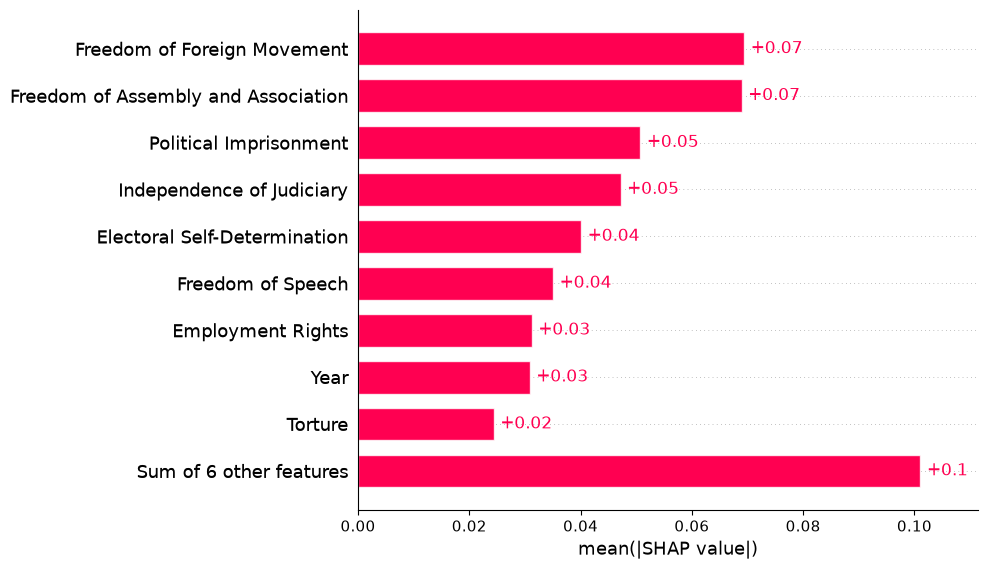

In [34]:
# Gráfico de barras
shap.plots.bar(shap_values)